In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Single Variable Calculus

The models of the Basics part were all trained by gradient descent. At each
step the optimizer evaluates the loss and its slope at the current weights,
moves the weights a little downhill, and repeats. It never sees the loss
anywhere else, so every step rests on a prediction: the slope at one point is
assumed to describe the loss a short distance away. How good is that
prediction, and how large a step does it allow?

A single weight already shows what the answer looks like. Take one training
example, one weight $w$, and the logistic loss $\ell(w)=\log(1+e^{-w})$. At
$w=0$ the loss is $0.693147$ and its slope is $-\tfrac12$. If the weight
moves to $w=0.1$, a straight line through $w=0$ with that slope predicts a
loss of $0.693147-0.05=0.643147$. The actual loss is $0.644397$, so the line
is off by only $0.00125$. The error has a simple form. It equals
$\tfrac12\cdot\tfrac14\cdot0.1^2$, where the number $\tfrac14$ measures how
much the graph of $\ell$ bends at $w=0$. The slope makes the prediction, and
the bend says how quickly the prediction goes wrong as the step grows.

This section builds the line from the first derivative and, from the second,
a parabola that also accounts for the bend. It proves the rules of
differentiation, bounds the error of each of the two models, and uses the
models to choose a safe step size for gradient descent and to run Newton's
method. It ends at the corner of $\mathrm{ReLU}$, where no line fits and
backpropagation must still return a slope.

The Basics (that section) defined the derivative, stated the rules
of differentiation, and used automatic differentiation as a tool. For a
network with loss $\ell(w_1,\ldots,w_n)$, holding every weight but $w_i$
fixed and replacing $w_i$ by $x$ gives a function of one variable,
$f(x)=\ell(w_1,\ldots,w_{i-1},x,w_{i+1},\ldots,w_n)$. One-variable calculus
studies such slices.

Our running function is the *softplus* $s(x)=\log(1+e^{x})$. It is the
one-variable slice $\log(e^0+e^x)$ of the log-sum-exp function that this
chapter uses throughout, and the opening's loss is $\ell(w)=s(-w)$.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## The Derivative

### The Difference Quotient

We want to measure how a function $f$ responds to a small change of its input
at one point $x$. Look at the graph near $x$. Zoom in far enough and the curve
cannot be told apart from a straight line
(the figure). The slope of that line is what we will call
the derivative.

![The curve $\sin(x^x)$ near $x_0=2$, in windows of half-width $0.6$, $0.06$ and $0.006$. As the window shrinks, the curve (solid) becomes indistinguishable from its tangent line (dashed).](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-zoom-sequence.svg)

A slope needs two points. Comparing the change in output with the change in
input between $x$ and a nearby point $x+\epsilon$ gives

$$
\frac{f(x+\epsilon) - f(x)}{(x+\epsilon) - x} = \frac{f(x+\epsilon) - f(x)}{\epsilon},
$$

the slope of the *secant* line through $(x, f(x))$ and
$(x+\epsilon, f(x+\epsilon))$. As $\epsilon$ shrinks, the second point slides
toward the first and the secant rotates toward the tangent
(the figure).

![The difference quotient is the slope of the secant through $(x, f(x))$ and $(x+\epsilon, f(x+\epsilon))$. As $\epsilon \to 0$, this slope approaches the tangent slope $f'(x)$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-secant-to-tangent.svg)

The smallest interesting case is a polynomial whose quotient we can also
expand by hand. Take $f(x) = x^2 + 1701(x-4)^3$ at $x = 4$. Does the secant
slope settle as $\epsilon$ shrinks?

In [ ]:
def f(x):
    return x**2 + 1701*(x-4)**3

# Slope of the secant through x=4, for shrinking epsilon
for epsilon in [0.1, 0.001, 0.0001, 0.00001]:
    print(f'epsilon = {epsilon:.5f} -> {(f(4+epsilon) - f(4)) / epsilon:.5f}')

The slopes $25.11$, $8.0027$, $8.00012$, $8.00001$ approach $8$. The algebra
says why. Expanding gives $f(4+\epsilon)-f(4)=8\epsilon+\epsilon^2+1701\epsilon^3$,
so the difference quotient is $8+\epsilon+1701\epsilon^2$. The cubic term
contributes $17$ at $\epsilon=0.1$ but only $1.7\times10^{-7}$ at
$\epsilon=10^{-5}$, and

$$
\lim_{\epsilon \rightarrow 0}\frac{f(4+\epsilon) - f(4)}{\epsilon} = 8.
$$

Thus the slope of $f$ at $4$ is $8$. The large coefficient $1701$ slows the
approach to the limit but does not change it. Automatic differentiation reaches
the same number without any $\epsilon$. It applies the rules derived below
exactly, and that section builds such a system.

### The Derivative and the Linear Approximation

The **derivative** of $f$ at $x$ is the limit of the secant slopes,

$$
f'(x) = \frac{df}{dx}(x) = \lim_{\epsilon \rightarrow 0}\frac{f(x+\epsilon) - f(x)}{\epsilon},
$$

whenever the limit exists, and $f$ is then called *differentiable* at $x$.
The derivative is the rate at which the output changes per unit change of the
input, at the point $x$. The computation above gives $f'(4)=8$. We write $f'$
or $\frac{df}{dx}$, and $\frac{d}{dx}[\ldots]$ when the function is a bulky
expression.

The limit can fail to exist. For $|x|$ at $0$ the quotient
$|\epsilon|/\epsilon$ is $+1$ for every $\epsilon>0$ and $-1$ for every
$\epsilon<0$, so it has no limit and $|x|$ has no derivative at $0$. The last
part of this section returns to such corners.

Rearranging the definition turns the derivative into a prediction. Let
$r(\epsilon)=f(x+\epsilon)-f(x)-\epsilon f'(x)$ be the error of the line; the
definition says that $r(\epsilon)/\epsilon\to0$. We write $o(\epsilon)$ for any
quantity $r(\epsilon)$ with $r(\epsilon)/\epsilon\to0$ as $\epsilon\to0$, and
obtain the **linear approximation**

$$
f(x+\epsilon) = f(x) + \epsilon f'(x) + o(\epsilon).
$$

A step $\epsilon$ changes the output by $\epsilon f'(x)$, up to an error that
vanishes faster than $\epsilon$. The converse holds as well: if
$f(x+\epsilon)=f(x)+a\epsilon+o(\epsilon)$ for some number $a$, dividing by
$\epsilon$ and letting $\epsilon\to0$ shows that $f$ is differentiable at $x$
with $f'(x)=a$. The expansion and the derivative therefore carry the same
information, and the proofs of the sum and chain rules below use this
direction.

Plotted against the input $x+\epsilon$, the line $f(x)+\epsilon f'(x)$ passes
through $(x,f(x))$ with slope $f'(x)$. It is the *tangent*, the limit of the
rotating secants. The opening's prediction is this line. With
$\ell'(0)=-\tfrac12$, a value we derive below, the linear approximation
predicts $\ell(0.1)\approx0.693147-0.1\cdot\tfrac12=0.643147$. The gap of
$0.00125$ to the true value $0.644397$ is the $o(\epsilon)$ term. It is of
order $\epsilon^2$, much smaller than $\epsilon=0.1$, and a computation below
measures how it shrinks.

## Computing Derivatives

Taking a limit for every new function would be slow. Instead we combine a
short table of derivatives with rules for sums, products, and compositions.
The Basics stated these rules; here each is proved from the linear
approximation and then applied to the running example.

### A Table of Common Derivatives

The following entries hold wherever the right-hand sides are defined: the
power rule for every real $n$ when $x>0$, and for integer $n$ wherever $x^n$
is defined; the logarithm for $x>0$.

* **Derivative of constants.** $\frac{d}{dx}c = 0$.
* **Derivative of linear functions.** $\frac{d}{dx}(ax) = a$.
* **Power rule.** $\frac{d}{dx}x^n = nx^{n-1}$.
* **Derivative of exponentials.** $\frac{d}{dx}e^x = e^x$.
* **Derivative of the logarithm.** $\frac{d}{dx}\log(x) = \frac{1}{x}$.
* **Derivative of sine.** $\frac{d}{dx}\sin(x) = \cos(x)$.
* **Derivative of cosine.** $\frac{d}{dx}\cos(x) = -\sin(x)$.

The exponential entry rests on a short argument that also says what makes the
base $e$ special.

**Proposition (exponentials).** *Let $a>0$ and suppose that $a^x$ has a
derivative at $x=0$; call it $c_a$. Then $\frac{d}{dx}a^x=c_a\,a^x$ for every
$x$.*

**Proof.** The difference quotient at $x$ factors as

$$
\frac{a^{x+\epsilon}-a^x}{\epsilon} = a^x\,\frac{a^\epsilon-1}{\epsilon}.
$$

The second factor is the difference quotient at $0$, which tends to $c_a$.
$\blacksquare$

The slope of an exponential is therefore proportional to its height, with one
constant per base. Numerically, $(2^\epsilon-1)/\epsilon=0.69315$ at
$\epsilon=10^{-6}$, and the same quotient for base $10$ is $2.30259$. The
number $e$ is the base whose constant is $1$, which gives the table's entry
$\frac{d}{dx}e^x=e^x$. The inverse-function rule below identifies $c_a$ for
every base.

### Rules for Combining Derivatives

The table covers only the building blocks. A loss combines them by sums,
products, quotients, and compositions, and the rules below give the
derivative of each combination from the derivatives of its parts. Let $g$ and
$h$ be differentiable at $x$; for the chain rule, let $h$ be
differentiable at $x$ and $g$ at $h(x)$. Then:

* **Sum rule.** $\frac{d}{dx}\bigl(g(x) + h(x)\bigr) = g'(x) + h'(x)$.
* **Product rule.** $\frac{d}{dx}\bigl(g(x)\, h(x)\bigr) = g(x)h'(x) + g'(x)h(x)$.
* **Quotient rule.** $\frac{d}{dx}\frac{g(x)}{h(x)} = \frac{g'(x)h(x) - g(x)h'(x)}{h(x)^2}$, where $h(x)\neq 0$.
* **Chain rule.** $\frac{d}{dx}g(h(x)) = g'(h(x))\, h'(x)$.

The proofs use one fact. **A function differentiable at $x$ is continuous at
$x$:** $g(x+\epsilon)-g(x)=\epsilon\cdot\frac{g(x+\epsilon)-g(x)}{\epsilon}$
tends to $0\cdot g'(x)=0$.

**Sum rule.** Adding the two linear approximations gives

$$
g(x+\epsilon) + h(x+\epsilon) = g(x) + h(x) + \epsilon\bigl(g'(x) + h'(x)\bigr) + o(\epsilon),
$$

because the sum of two quantities that vanish faster than $\epsilon$ also
vanishes faster than $\epsilon$. By the converse of the linear approximation,
the coefficient of $\epsilon$ is the derivative: the two first-order changes
add. $\blacksquare$

**Product rule.** Adding and subtracting $g(x+\epsilon)h(x)$ in the numerator
splits the difference quotient of the product into two quotients we know,

$$
\frac{g(x+\epsilon)h(x+\epsilon)-g(x)h(x)}{\epsilon}
= g(x+\epsilon)\,\frac{h(x+\epsilon)-h(x)}{\epsilon} + h(x)\,\frac{g(x+\epsilon)-g(x)}{\epsilon}.
$$

As $\epsilon\to0$ the right-hand side tends to $g(x)h'(x)+h(x)g'(x)$, because
$g(x+\epsilon)\to g(x)$ by continuity. $\blacksquare$

The rule describes the growth of a rectangle with sides $g$ and $h$.
When both sides stretch, the area gains two strips, $g\cdot\Delta h$ and
$h\cdot\Delta g$, plus a corner $\Delta g\,\Delta h$ whose size is of order
$\epsilon^2$ and drops out of the rate.

**Chain rule.** The argument feeds the change of the inner function into the
linear approximation of the outer one. Since $g$ is differentiable at $h(x)$,
the quantity $\rho(t)=\frac{g(h(x)+t)-g(h(x))}{t}-g'(h(x))$ for $t\neq0$, with
$\rho(0)=0$, tends to $0$ as $t\to0$. Thus for every $t$,

$$
g(h(x)+t) = g(h(x)) + \bigl(g'(h(x)) + \rho(t)\bigr)\,t.
$$

Put $t=h(x+\epsilon)-h(x)=\epsilon h'(x)+o(\epsilon)$, which tends to $0$
with $\epsilon$, so that $\rho(t)\to0$ as well. Then

$$
g(h(x+\epsilon)) - g(h(x)) = \bigl(g'(h(x)) + \rho(t)\bigr)\bigl(\epsilon h'(x) + o(\epsilon)\bigr)
= \epsilon\, g'(h(x))\, h'(x) + o(\epsilon),
$$

since every product other than $g'(h(x))\,\epsilon h'(x)$ contains a factor
that vanishes faster than $\epsilon$. The converse of the linear approximation
gives the rule. $\blacksquare$

Rates multiply along a composition: if $h$ moves three times as fast as $x$
and $g$ moves twice as fast as $h$, then $g\circ h$ moves six times as fast as
$x$. Applied layer by layer to a network, the chain rule produces a product of
local slopes, and evaluating that product is what backpropagation does. The
quotient rule follows from the product and chain rules applied to
$g\cdot h^{-1}$, as exercise 1
shows.

### Inverse Functions

The chain rule also differentiates a function that undoes another. A function
$g$ with $g(f(x))=x$ for all $x$ near some point is an *inverse* of $f$ there.
Suppose such a $g$ exists and is differentiable at $f(x)$. Both hold whenever
$f'$ is continuous and nonzero near $x$, by the inverse function theorem
[@Rudin.1976], which we use without proof.
Differentiating both sides with the chain rule gives

$$
g'(f(x))\,f'(x) = 1, \qquad\text{so}\qquad g'(y) = \frac{1}{f'(g(y))} \quad\text{at } y = f(x).
$$

The slope of the inverse is the reciprocal of the slope of $f$, read at the
matching point. The graph of $g$ is the graph of $f$ reflected in the diagonal,
and the reflection turns rise over run upside down.

The logarithm undoes $e^x$, so $\log'(y)=1/e^{\log y}=1/y$, the table's fifth
entry. The hypothesis $f'\neq0$ is needed. For $x^3$ we have $f'(0)=0$, and
the formula gives no slope at $y=0$. The inverse $x^{1/3}$ has no derivative
at $0$: its quotient $\epsilon^{1/3}/\epsilon=\epsilon^{-2/3}$ grows without
bound, and the graph has a vertical tangent there.

The rule also settles the constants of the exponentials. Since
$a^x=e^{x\log a}$, the chain rule gives $c_a=\log a$, and $\log2=0.693$ and
$\log10=2.303$ are the constants measured above.

### The Softplus, the Sigmoid, and the Logit

We now apply the rules to the running function. The chain rule with outer
function $\log$ and inner function $1+e^x$ gives

$$
s'(x) = \frac{e^x}{1+e^x} = \frac{1}{1+e^{-x}} = \sigma(x),
$$

so the slope of the softplus is the *sigmoid* $\sigma$. Applying the chain rule
again to $\sigma=(1+e^{-x})^{-1}$, with outer function $u^{-1}$ and inner
function $1+e^{-x}$ of slope $-e^{-x}$, gives

$$
\sigma'(x) = \frac{e^{-x}}{(1+e^{-x})^2} = \sigma(x)\bigl(1-\sigma(x)\bigr),
$$

because $1-\sigma(x)=e^{-x}/(1+e^{-x})$. Thus the slope of the sigmoid is
largest where $\sigma=\tfrac12$: $\sigma(0)=\tfrac12$ and $\sigma'(0)=\tfrac14$.
The inverse of $\sigma$ is the *logit*
$\mathrm{logit}(p)=\log\frac{p}{1-p}$, and the inverse-function rule gives
$\mathrm{logit}'(p)=1/\sigma'(\mathrm{logit}\,p)=\frac{1}{p(1-p)}$. At
$p=\tfrac12$ this is $4=1/\tfrac14$.

Now the opening's numbers follow. The loss is $\ell(w)=s(-w)$, so the chain
rule gives $\ell'(w)=-\sigma(-w)$ and $\ell'(0)=-\tfrac12$. Differentiating
once more (the derivative of the derivative, which the curvature part of this
section studies) gives $\ell''(w)=\sigma(-w)\bigl(1-\sigma(-w)\bigr)$ and
$\ell''(0)=\tfrac14$. Does the gap between $\ell(\epsilon)$ and the line
$\ell(0)-\tfrac12\epsilon$ shrink like $\epsilon^2$, with constant
$\tfrac12\ell''(0)=\tfrac18$?

In [ ]:
# The logistic loss l(w) = log(1 + e^{-w}) near w = 0, where l'(0) = -1/2
def ell(w):
    return np.log(1 + np.exp(-w))

for eps in [0.1, 0.01, 0.001]:
    line = ell(0) - 0.5 * eps          # the linear approximation
    gap = ell(eps) - line
    print(f'eps = {eps:<5}: l = {ell(eps):.6f}, line = {line:.6f}, '
          f'gap = {gap:.2e}, gap / eps^2 = {gap / eps**2:.4f}')

The gap drops a hundredfold for every tenfold smaller step, and
$\text{gap}/\epsilon^2$ settles at $0.125=\tfrac12\ell''(0)$. The error of the
linear approximation is of second order here, with a constant set by the
curvature; the Taylor polynomial below explains the $\tfrac18$.

Automatic differentiation applies these same rules mechanically. Does it
reproduce the hand results $f'(4)=8$ for the cubic and $s'(0)=\sigma(0)=\tfrac12$?

In [ ]:
# Autograd applies the rules: f'(4) = 8 for the cubic, softplus'(0) = sigma(0) = 1/2
def softplus(x):
    return jnp.log(1 + jnp.exp(x))

for name, fn, x0 in [("f'(4)", f, 4.0), ("softplus'(0)", softplus, 0.0)]:
    print(f'autograd: {name} = {jax.grad(fn)(x0):.3f}')

Both values agree with the hand computation. Anything built from the table by
sums, products, quotients, and compositions can be differentiated this way.
The next question is what the slope at a point says about the function on a
whole interval.

## The Mean Value Theorem

We have been reading the derivative as if it described the function nearby: a
positive slope means the function climbs, and a point with slope zero is a
candidate minimum. Both statements infer the behavior of $f$ on an interval
from its derivative at single points. The Mean Value Theorem justifies them.
In a picture (the figure), the chord joining the endpoints of the
graph over $[a,b]$ is parallel to the tangent at some interior point.

![Over the interval from $a$ to $b$, the secant chord through the endpoints has slope equal to the average rate of change; the Mean Value Theorem says some interior point $\xi$ has a tangent of that same slope, parallel to the chord.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-mvt.svg)

For $f(x)=x^2$ on $[0,2]$ the chord has slope $(4-0)/2=2$, and the tangent
slope $f'(\xi)=2\xi$ equals $2$ at $\xi=1$, the midpoint. The theorem needs a
derivative at every interior point. The function $|x|$ on $[-1,1]$ has
$f(-1)=f(1)$, so its chord is flat, yet no interior point has slope $0$: the
slopes are $-1$ on the left, $+1$ on the right, and at $0$ there is none.

**Proposition (Mean Value Theorem).** *If $f$ is continuous on $[a,b]$ and
differentiable on $(a,b)$, then there is a point $\xi \in (a,b)$ with*

$$
f'(\xi) = \frac{f(b) - f(a)}{b - a}.
$$

**Proof.** First take the flat case $f(a) = f(b)$, which is Rolle's theorem.
We use one fact from real analysis, the **extreme value theorem**: a
continuous function on a closed interval attains a maximum and a minimum
[@Rudin.1976]. If both occur at the endpoints then $f$ is constant and
$f' \equiv 0$ inside. Otherwise an extremum sits at some interior $\xi$, say a
maximum, so $f(\xi + \epsilon) - f(\xi) \le 0$ on both sides. The difference
quotient is then $\le 0$ for $\epsilon > 0$ and $\ge 0$ for $\epsilon < 0$.
Since $f$ is differentiable at $\xi$, both one-sided limits equal $f'(\xi)$,
and a number that is both $\le 0$ and $\ge 0$ is zero; a minimum is handled
the same way.

For the general case, subtract the chord. The tilted function
$\tilde f(x) = f(x) - \frac{f(b)-f(a)}{b-a}(x - a)$ has
$\tilde f(a) = \tilde f(b) = f(a)$, so the flat case gives a $\xi$ with
$\tilde f'(\xi) = 0$, which is the equation. $\blacksquare$

The average rate of change over an interval is attained as an instantaneous
rate at some interior point. Two consequences are the facts we have been
using.

1. *If $f'>0$ on an interval, then $f$ is strictly increasing there.* For any
   $x_1<x_2$ in the interval, the equation gives
   $f(x_2)-f(x_1)=f'(\xi)(x_2-x_1)>0$ for some $\xi$ between them. Likewise
   $f'<0$ gives a strictly decreasing $f$, and $f'=0$ a constant one.
2. *If $f'<0$ on $(x_0-\delta,x_0)$ and $f'>0$ on $(x_0,x_0+\delta)$ for some
   $\delta>0$, and $f$ is continuous at $x_0$, then $x_0$ is a strict local
   minimum.* Apply the first consequence on each side: $f$ falls into $x_0$ and
   rises out of it.

With the theorem, the sign of $f'$ on an interval decides whether $f$ rises or
falls there. For the running function, $s'=\sigma>0$ everywhere, so the
softplus is strictly increasing on all of $\mathbb R$.

## Gradient Descent in One Variable

### The Gradient-Descent Step

The linear approximation predicts the effect of any step $\epsilon$:
$f(x+\epsilon)\approx f(x)+\epsilon f'(x)$. To lower $f$ we choose $\epsilon$
with the sign opposite to the slope. Taking $\epsilon=-\eta f'(x)$ with a
*step size* $\eta>0$, the line predicts the change

$$
f\bigl(x-\eta f'(x)\bigr) - f(x) \approx -\eta\, f'(x)^2,
$$

which is negative whenever $f'(x)\neq0$. Whatever the sign of the slope,
stepping against it lowers the linear model by an amount proportional to the
slope squared (the figure).

![One gradient-descent step on a 1-D bowl. At $x$ the tangent line has slope $f'(x)$; the step $-\eta f'(x)$ moves opposite the slope and lands at $x - \eta f'(x)$, lower on the curve, with the drop equal to $\eta f'(x)^2$ to first order.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-gd-step.svg)

Repeating the step gives one-dimensional **gradient descent**,

$$
x_{t+1} = x_t - \eta\, f'(x_t).
$$

Each iterate moves against the current slope, and the iteration stops moving
at a *stationary point*, where $f'(x_t)=0$. For a network, each coordinate of
the weight update $w_i\leftarrow w_i-\eta\,\partial\ell/\partial w_i$ has this
form, with all coordinates updated at once. On the running loss from $w=0$,
the slope is $\ell'(0)=-\tfrac12$, so the step is $\epsilon=\eta/2$ and the
predicted drop is $\eta/4$.

The prediction $-\eta f'(x)^2$ is negative for every $\eta$, however large.
Yet a large step can overshoot the minimum and land higher than it started.
The line does not register this, because it carries no information about how
the graph bends. The simplest bowl, $x^2$, shows where its prediction fails.

### The Quadratic Case

For $f(x)=x^2$ the slope is $f'(x)=2x$, and the gradient-descent step becomes

$$
x_{t+1} = x_t - \eta\,(2x_t) = (1 - 2\eta)\, x_t.
$$

Each step multiplies the iterate by the same factor, so $x_t=(1-2\eta)^t x_0$.
The iterates converge to the minimum $x = 0$ if and only if $|1 - 2\eta| < 1$,
that is, for $0 < \eta < 1$. Inside this range a small $\eta$ converges slowly
and monotonically, $\eta = \tfrac12$ reaches the minimum in one step, and
$\tfrac12 < \eta < 1$ overshoots and alternates inward. At $\eta = 1$ the
iterates alternate forever between $\pm x_0$, and for $\eta > 1$ they diverge.
Do ten steps from $x_0=1$ show these regimes? The next cell runs the recursion
for five step sizes, prints the tenth iterate, and plots the trajectories.

eta = 0.05 -> x_10 = +0.34868
eta = 0.50 -> x_10 = +0.00000
eta = 0.90 -> x_10 = +0.10737
eta = 1.00 -> x_10 = +1.00000
eta = 1.10 -> x_10 = +6.19174


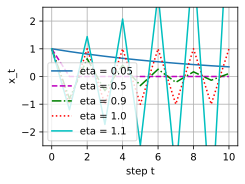

In [5]:
# Gradient descent on f(x) = x^2 from x0 = 1, for several step sizes
def gd(eta, steps=10, x0=1.0):
    xs = [x0]
    for _ in range(steps):
        xs.append(xs[-1] - eta * (2 * xs[-1]))  # x <- x - eta * f'(x)
    return xs

etas = [0.05, 0.5, 0.9, 1.0, 1.1]
trajectories = [gd(eta) for eta in etas]
for eta, xs in zip(etas, trajectories):
    print(f'eta = {eta:.2f} -> x_10 = {xs[-1]:+.5f}')
d2l.plot(list(range(11)), trajectories, 'step t', 'x_t', ylim=[-2.5, 2.5],
         legend=[f'eta = {eta}' for eta in etas],
         fmts=('-', 'm--', 'g-.', 'r:', 'c-'))

Each curve shows one regime. After ten steps, $\eta=0.05$ has reached only
$x_{10}=0.349$, $\eta=0.5$ sits at $0$, $\eta=0.9$ has alternated down to
$0.107$, $\eta=1$ is back at $1$, and $\eta=1.1$ has grown to $6.19$. The
threshold $\eta=1$, where the iterates cycle, separates the converging runs
from the others. Here $1=2/f''$, since $f''\equiv2$. The descent lemma below
shows that a bound $L$ on the curvature gives the threshold $2/L$ for every
function.

## Curvature and Taylor Series

How far can the line be trusted, and how large a step is safe? Both answers
need the rate at which the slope itself changes.

### The Second Derivative

The derivative $f'$ is itself a function, so we can differentiate it again.
The result is the *second derivative*,
$f''=\frac{d^2f}{dx^2}=\frac{d}{dx}\bigl(\frac{df}{dx}\bigr)$: the rate of
change of the slope. Repeating gives the $n$-th derivative,

$$
f^{(n)}(x) = \frac{d^{n}f}{dx^{n}} = \left(\frac{d}{dx}\right)^{n} f.
$$

A positive $f''$ means the slope increases, so the graph bends upward; a
negative $f''$ means it bends downward. At a stationary point this sign
decides between a minimum and a maximum.

**Proposition (second-derivative test).** *Let $f'(x_0)=0$ and let $f''(x_0)$
exist. If $f''(x_0)>0$, then $x_0$ is a strict local minimum; if
$f''(x_0)<0$, it is a strict local maximum.*

**Proof.** Since $f'(x_0)=0$, the definition of $f''(x_0)$ reads
$f''(x_0)=\lim_{\epsilon\to0}f'(x_0+\epsilon)/\epsilon$. If this limit is
positive, the quotient $f'(x_0+\epsilon)/\epsilon$ is positive for all small
$\epsilon\neq0$, so $f'(x_0+\epsilon)$ has the sign of $\epsilon$: negative
just left of $x_0$, positive just right of it. The second consequence of the
Mean Value Theorem then makes $x_0$ a strict local minimum. The case
$f''(x_0)<0$ is the same with signs reversed. $\blacksquare$

The step that is not routine is the last one: a sign pattern of the slope at
points becomes a minimum on an interval only through the Mean Value Theorem.
The test certifies a neighborhood of $x_0$, not the whole function. With many
variables, the signs of the eigenvalues of the matrix of second derivatives
play the same role.

![The second-derivative test. Rows: $f''(0)>0$ (a bowl, minimum), $f''(0)<0$ (a dome, maximum), and $f''(0)=0$, where $x^3$, $x^4$ and $-x^4$ share $f'(0)=f''(0)=0$ yet have an inflection point, a minimum and a maximum at $0$. Columns: $f''$, $f'$, $f$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-second-derivative-1d.svg)

the figure shows the three cases. In the first
row $f''>0$ keeps the slope rising through zero, which makes an upward bowl;
in the second row $f''<0$ makes a downward-opening dome. At a stationary point
with $f''(x_0)=0$ the test is silent: $x^3$, $x^4$ and $-x^4$ all have
$f'(0)=f''(0)=0$, yet $0$ is an inflection point, a minimum, and a maximum
respectively. Exercise 5
derives the test that higher derivatives give in this case.

### The Taylor Polynomial

The line matches the value and the slope of $f$ at a base point $x_0$. A
parabola can also match the curvature. A quadratic $q(x)=ax^2+bx+c$ has

$$
q'(x) = 2ax + b, \qquad q''(x) = 2a,
$$

so its second derivative is the constant $2a$, and matching the curvature of
$f$ fixes $a=f''(x_0)/2$. Matching value and slope as well fixes $b$ and $c$.
For $f(x) = \sin(x)$, with $\sin'=\cos$ and $\sin''=-\sin$, the best parabola
at $x_0$ is

$$
q(x) = \sin(x_0) + \cos(x_0)\,(x - x_0) - \tfrac{1}{2}\sin(x_0)\,(x-x_0)^2.
$$

Because it also follows the bend, it stays close to the curve over a wider
interval than the tangent (the figure, drawn at a base
point where $\sin x_0\neq0$, so the parabola is curved).

![The sine curve with its two local models at $x_0$: the tangent line matches value and slope, while the best parabola also matches curvature and remains accurate over a wider interval.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-best-parabola.svg)

For the running function at $x_0=0$, the values $s(0)=\log2$, $s'(0)=\tfrac12$
and $s''(0)=\tfrac14$ give the best parabola
$\log2+\tfrac{x}{2}+\tfrac{x^2}{8}$. Its quadratic coefficient $\tfrac18$ is the
constant that $\text{gap}/\epsilon^2$ settled at in the check of the opening's
numbers.

The same construction works to any degree. The degree-$n$ **Taylor
polynomial** of $f$ at $x_0$ is

$$
P_n(x) = \sum_{i = 0}^{n} \frac{f^{(i)}(x_0)}{i!}(x-x_0)^{i},
$$

the unique polynomial of degree at most $n$ whose derivatives through order
$n$ match those of $f$ at $x_0$. The factorials appear because differentiating
$(x-x_0)^i$ $i$ times at $x_0$ gives $i!$, while every other term gives $0$.
For $P_1$ this is the tangent and for $P_2$ the best parabola. How well do the
higher degrees follow $e^x$ away from $x_0=0$, where every derivative equals
$1$?

In [ ]:
# The Taylor polynomials P_1, P_2, P_5 of e^x at 0, against e^x
xs = np.arange(0, 3, 0.01)
P = [sum(xs**k / math.factorial(k) for k in range(n + 1)) for n in (1, 2, 5)]
d2l.plot(xs, [np.exp(xs)] + P, 'x', 'f(x)', legend=['exp', 'P_1', 'P_2', 'P_5'])

Each higher degree tracks the curve farther from the base point. Near $x_0$
all of them are accurate; the question is how fast the error grows with the
distance.

### The Lagrange Remainder

The Mean Value Theorem gives an exact expression for the error of $P_n$, with
one unknown point.

**Proposition (Lagrange remainder).** *If $f$ is $(n+1)$-times differentiable
on an open interval containing $x_0$ and $x$, with $x\neq x_0$, then*

$$
f(x) = P_n(x) + R_n(x), \qquad R_n(x) = \frac{f^{(n+1)}(\xi)}{(n+1)!}\,(x - x_0)^{n+1},
$$

*for some $\xi$ strictly between $x_0$ and $x$. The case $n = 0$ is the Mean
Value Theorem, $f(x) = f(x_0) + f'(\xi)(x - x_0)$.*

**Proof.** Fix $x$ and make the base point the variable: for $t$ between
$x_0$ and $x$, let

$$
G(t) = f(x) - \sum_{k=0}^{n} \frac{f^{(k)}(t)}{k!}\,(x-t)^k - M\,\frac{(x-t)^{n+1}}{(n+1)!},
$$

and choose the constant $M$ so that $G(x_0)=0$. The proof has three steps.

First, the endpoints vanish. The choice of $M$ gives $G(x_0)=0$, while
$G(x)=0$ because every positive power of $(x-t)$ vanishes at $t=x$ and the
$k=0$ term becomes $f(x)-f(x)$. Rolle's theorem therefore supplies a point
$\xi$ strictly between $x_0$ and $x$ with $G'(\xi)=0$.

Second, differentiate the sum. By the product rule, the $k$-th summand with
$k\geq1$ contributes

$$
-\frac{f^{(k+1)}(t)}{k!}(x-t)^k + \frac{f^{(k)}(t)}{(k-1)!}(x-t)^{k-1}
$$

to $G'(t)$, and the $k=0$ term contributes $-f'(t)$. The terms cancel in
pairs along the sum (it telescopes), leaving only the last derivative:

$$
G'(t) = -\frac{f^{(n+1)}(t)}{n!}\,(x-t)^n + M\,\frac{(x-t)^n}{n!}.
$$

Third, set $t=\xi$. Since $(x-\xi)^n\neq0$, the equation $G'(\xi)=0$ forces
$M=f^{(n+1)}(\xi)$. Substituting this value into $G(x_0)=0$ gives
the equation. $\blacksquare$

The remainder has the shape of the next Taylor term, with the derivative
evaluated at an unknown interior point $\xi$ instead of at $x_0$. When
$f^{(n+1)}$ is bounded near $x_0$, the error therefore scales as
$|x-x_0|^{n+1}$: each additional matched derivative raises the order by one.

For the running function, $s'''=\sigma(1-\sigma)(1-2\sigma)$ vanishes at $0$
and $s''''(0)=-\tfrac18$, so

$$
P_4(x) = \log 2 + \frac{x}{2} + \frac{x^2}{8} - \frac{x^4}{192}.
$$

At $x=0.5$ this gives $0.974072$ against $s(0.5)=0.974077$, an error of
$5\times10^{-6}$. The error is even smaller than the $x^5$ scale suggests,
because $s(x)-\tfrac{x}{2}=\log\bigl(2\cosh\tfrac{x}{2}\bigr)$ is an even
function and the next nonzero term is of sixth order.

The scaling is a prediction we can test. If the error of $P_n$ on the window
$|x|\le h$ grows like $h^{n+1}$, halving the window should divide the worst
error by $2^{n+1}$: by $4$ for the tangent, $8$ for the parabola, and $16$ for
the cubic. Does it, for $e^x$ at $x_0=0$?

In [ ]:
# Max error of P_n for e^x on |x| <= h. Lagrange predicts error ~ h^(n+1),
# so halving h should divide it by 2^(n+1)
def taylor_error(n, h, m=1000):
    x = h * np.arange(-m, m + 1) / m
    P = sum(x**k / math.factorial(k) for k in range(n + 1))
    return np.max(np.abs(np.exp(x) - P))

hs = [0.4, 0.2, 0.1, 0.05]
errs = [[taylor_error(n, h) for h in hs] for n in (1, 2, 3)]
for n, e in zip((1, 2, 3), errs):
    ratios = ' '.join(f'{a / b:.1f}' for a, b in zip(e, e[1:]))
    print(f'n = {n}: ratios between successive windows {ratios}, '
          f'predicted {2**(n + 1)}')
d2l.plot(hs, errs, 'window h', 'max error', xscale='log', yscale='log',
         legend=['n = 1', 'n = 2', 'n = 3'])

The measured ratios sit near $4$, $8$, and $16$, and on the log–log plot the
three error curves are straight lines with slopes $2$, $3$, and $4$, that is,
$n+1$. The ratios overshoot slightly on the wider windows because the factor
$e^{\xi}$ in the remainder is larger there.

The remainder also settles whether the infinite series reproduces the function.
For $e^x$ every derivative is $e^x$, so the equation with
$x_0=0$ gives

$$
\bigl|e^x - P_n(x)\bigr| = \frac{e^{\xi}\,|x|^{n+1}}{(n+1)!} \le \frac{e^{|x|}\,|x|^{n+1}}{(n+1)!}.
$$

For fixed $x$ the right-hand side tends to $0$ as $n\to\infty$, because
factorials outgrow powers. Thus

$$
e^{x} = \sum_{n = 0}^\infty \frac{x^{n}}{n!} = 1 + x + \frac{x^2}{2} + \frac{x^3}{6} + \cdots
$$

on all of $\mathbb R$. A function is **real analytic** at $x_0$ if its Taylor
series there converges on a neighborhood of $x_0$ and its sum equals $f$
throughout that neighborhood. The functions $e^x$ and $\cos x$ are real
analytic at every point, with series that converge to them on all of
$\mathbb R$.

Infinitely many derivatives are not enough for this. The function
$f(x) = e^{-1/x^2}$, with $f(0) = 0$, is infinitely differentiable everywhere,
and every derivative vanishes at $0$. Its Taylor series at $x_0 = 0$ is
therefore identically zero. The series converges on the whole line, but to the
zero function, and agrees with $f$ only at $x=0$
(the figure). In practice we use the finite
polynomials $P_n$, whose error the equation bounds directly.

![The smooth function $f(x) = e^{-1/x^2}$ has every derivative equal to zero at the origin, so its Taylor series there is identically zero. The series converges everywhere yet agrees with $f$ only at $x = 0$: smooth does not imply analytic.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-smooth-not-analytic.svg)

### The Descent Lemma

On $x^2$ we found the threshold $\eta<1=2/f''$. Does a bound on the curvature
give a guarantee of descent for every function? The Lagrange remainder with
$n=1$ answers yes.

**Proposition (descent lemma).** *Let $f$ be twice differentiable on an open
interval $I$ containing $x$ and $x-\eta f'(x)$, with $|f''|\le L$ on $I$. Then*

$$
f\bigl(x - \eta\, f'(x)\bigr) \;\le\; f(x) - \eta\Bigl(1 - \frac{L\eta}{2}\Bigr)f'(x)^2.
$$

*In particular $f$ strictly decreases whenever $0 < \eta < 2/L$ and
$f'(x) \neq 0$, and the guaranteed decrease is largest at $\eta = 1/L$, where
it is $f'(x)^2/(2L)$.*

**Proof.** For a step $u$, the Lagrange remainder with $n=1$ gives
$f(x+u)=f(x)+f'(x)u+\tfrac12f''(\xi)u^2\le f(x)+f'(x)u+\tfrac L2u^2$. Put
$u=-\eta f'(x)$; the right-hand side becomes
$f(x)-\eta(1-L\eta/2)f'(x)^2$. The bracket is positive for $\eta<2/L$, and the
coefficient $\eta(1-L\eta/2)$ is largest at $\eta=1/L$. $\blacksquare$

The lemma replaces the actual bend $f''(\xi)$ by its worst case $L$. The
resulting quadratic $f(x)+f'(x)u+\tfrac L2u^2$ is a ceiling that touches $f$ at
$x$ and lies above it on $I$. Its minimizer is the step $\eta=1/L$
(the figure). This bound is the standard tool of smooth
optimization [@Nesterov.2018]. It also holds when $f'$ is only
*$L$-Lipschitz*, meaning that slopes at two points differ by at most $L$ times
their distance, $|f'(u)-f'(v)|\le L|u-v|$. That is the form used for functions
of many variables, and exercise
2 proves it.

![For $|f''|\le L$, $f(x) + f'(x)u + \frac{L}{2}u^2$ is a quadratic upper bound in the step $u$ that equals $f$ at the base point. The gradient step with $\eta = 1/L$ minimizes this bound and guarantees a decrease of at least $\frac{1}{2L}f'(x)^2$. Here $f(x) = \sin(2x)$ with $L = 4$, and the actual decrease exceeds the worst-case guarantee.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-descent-lemma.svg)

For $x^2$ we have $f''\equiv2$, so $L=2$, and the threshold $2/L=1$ is the
one found from the closed form. On the running loss,
$\ell''(w)=\sigma(-w)\bigl(1-\sigma(-w)\bigr)\le\tfrac14$, with the maximum
$\tfrac14$ at $w=0$, so $L=\tfrac14$ and every $\eta<8$ decreases $\ell$ from
any starting weight. From $w=0$ with $\eta=1$ the step lands at $w_1=0.5$. The
bound promises $0.693147-(1-\tfrac18)\cdot\tfrac14=0.4744$, and the actual
value is $\ell(0.5)=0.4741$. The bound is nearly tight because the curvature
along this step is close to its maximum $L$. With $\eta=4=1/L$ the bound is
$0.1931$ and the actual value $\ell(2)=0.1269$: the curvature falls off away
from $0$, so the function descends further than the worst case allows for.

### Newton's Method

The descent lemma uses the worst-case curvature $L$. Using the actual
curvature $f''(x_t)$ at the current iterate gives a step that is exact on
parabolas. The model of $f$ at $x_t$ is the Taylor polynomial $P_2$,

$$
q(x) = f(x_t) + f'(x_t)\,(x - x_t) + \tfrac{1}{2}f''(x_t)\,(x - x_t)^2.
$$

When $f''(x_t)>0$ the parabola opens upward and has a unique minimizer.
Solving $q'(x) = f'(x_t) + f''(x_t)(x - x_t) = 0$ gives the update of
**Newton's method**:

$$
x_{t+1} = x_t - \frac{f'(x_t)}{f''(x_t)}.
$$

The step is a gradient step with the local step size $1/f''(x_t)$, and on any
parabola it reaches the minimizer in one step. the figure
shows one step on $f(x)=x^4/4-x$, whose minimizer is $x^\star=1$. At $x_t=2$
the values are $f=2$, $f'=7$, $f''=12$, so $x_{t+1}=2-7/12=1.4167$.

![One Newton step on $f(x)=x^4/4-x$ from $x_t=2$. The parabola $q$ matches the value, slope and curvature of $f$ at $x_t$; its minimizer is the next iterate $x_{t+1}=x_t-f'(x_t)/f''(x_t)=2-7/12$, closer to the minimizer $x^\star=1$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-newton-step.svg)

How fast does the error shrink? The next cell continues the iteration from
$x_0=2$, printing the error at each step. It then runs Newton's method from
$x_0=1.4$ on a second function, $x\arctan x-\tfrac12\log(1+x^2)$, discussed
below.

In [ ]:
# Newton on f(x) = x^4/4 - x: solve f'(x) = x^3 - 1 = 0, root x* = 1
x = 2.0
for t in range(6):
    print(f't = {t}: x = {x:.12f}, error = {abs(x - 1):.1e}')
    x = x - (x**3 - 1) / (3 * x**2)  # x - f'(x) / f''(x)

# Newton on the convex f(x) = x arctan(x) - log(1 + x^2)/2,
# with f' = arctan(x) and f'' = 1/(1 + x^2)
x, xs = 1.4, []
for t in range(6):
    x = x - math.atan(x) * (1 + x**2)
    xs.append(x)
print('from x0 = 1.4:', ', '.join(f'{v:.2f}' for v in xs))

On $x^4/4-x$ the errors run $1.0$, $0.42$, $0.11$, $1.1\times10^{-2}$,
$1.1\times10^{-4}$, $1.2\times10^{-8}$: after the first steps, each step
squares the previous error and doubles the number of correct digits. Gradient
descent on $x^2$ shrank the error by the fixed factor $|1-2\eta|$ per step,
which gains a fixed number of digits per step. The Lagrange remainder explains
the squaring.

**Proposition (Newton's error recursion).** *Let $f$ be three times
differentiable on an open interval containing $x_t$ and a stationary point
$x^\star$, let $f''(x_t)\neq0$, and write $e_t=x_t-x^\star$. Then*

$$
e_{t+1} = \frac{f'''(\xi_t)}{2f''(x_t)}\,e_t^2
$$

*for some $\xi_t$ between $x_t$ and $x^\star$.*

**Proof.** Apply the equation with $n=1$ to the function $f'$,
with base point $x_t$, evaluated at $x^\star$. Since $x^\star-x_t=-e_t$ and
$f'(x^\star)=0$,

$$
0 = f'(x_t) - f''(x_t)\,e_t + \tfrac12 f'''(\xi_t)\,e_t^2.
$$

Divide by $f''(x_t)$ and use $e_{t+1}=e_t-f'(x_t)/f''(x_t)$ from
the equation. $\blacksquare$

The new error is the square of the old one times a factor that tends to
$f'''(x^\star)/(2f''(x^\star))$ as the iterates converge. For $x^4/4-x$ at
$x^\star=1$ that factor is $6/(2\cdot3)=1$, and the printed errors give
$e_{t+1}/e_t^2\approx0.42$, $0.64$, $0.87$, $0.99$, approaching $1$. In
general, if $f''$ is Lipschitz near a local minimizer $x^\star$ with
$f''(x^\star)>0$ and the iteration starts close enough, Newton's method
converges quadratically [@Nocedal.Wright.2006].

"Close enough" cannot be dropped, even for a strictly convex function. The
function $f(x)=x\arctan x-\tfrac12\log(1+x^2)$ has $f'(x)=\arctan x$ and
$f''(x)=1/(1+x^2)>0$, so it is strictly convex with its unique minimum at $0$.
From $x_0=1.4$, the second loop of the cell printed the iterates
$-1.41, 1.45, -1.55, 1.85, -2.89, 8.71$: Newton's method diverges. From
$x_0=1.3$ it converges ($-1.16$, $0.86$, $-0.37$, $0.03$, …), and the boundary
between the two behaviors lies near $x_0\approx1.39$.

The model shows the cause. Far from $0$ the curvature $1/(1+x^2)$ is small, so
the parabola $q$ is flat and its minimizer lies far beyond $x^\star$.
Shortening the step by a factor $\alpha_t<1$, chosen at each iteration so that
$f$ decreases, is called *damping*. It restores convergence here: from
$x_0=1.4$, the factor $\alpha=\tfrac12$ lands at $-0.007$ in one step. No
fixed $\alpha$ works from every start, because for large $|x_t|$ the full step
grows like $\tfrac\pi2x_t^2$. that section develops
damping, together with the cost of a Newton step in many dimensions.

## Nondifferentiable Points

Every $\mathrm{ReLU}$ network has corners: $\mathrm{ReLU}(x)=\max(0,x)$ has
no derivative at $0$. Backpropagation still returns a number there. Which
number is it, and is it a valid slope?

### One-Sided Derivatives

The difference quotient the equation shows the trouble directly.
For $f(x) = |x|$ at $x = 0$,

$$
\frac{|0+\epsilon| - |0|}{\epsilon} = \frac{|\epsilon|}{\epsilon} =
\begin{cases} +1 & \epsilon > 0, \\ -1 & \epsilon < 0. \end{cases}
$$

The quotient is constant on each side, and the two constants differ. Coming
from the right the function rises with slope $+1$; coming from the left it
falls with slope $-1$. These are the **one-sided derivatives**
$f'_+(0) = +1$ and $f'_-(0) = -1$, and the ordinary derivative exists only when
they agree. For $\mathrm{ReLU}$ at $0$ the same computation gives
$f'_-(0) = 0$, flat on the left, and $f'_+(0) = 1$ on the right. What does
autograd return at these corners?

In [ ]:
# What autograd returns at the corner, where no derivative exists
for name, fn in [('d|x|/dx', jnp.abs), ("ReLU'", jax.nn.relu)]:
    print(f"{name} at 0: autograd returns {jax.grad(fn)(0.0):.1f}")

For $\mathrm{ReLU}'$ at $0$ autograd returns $0$, the left-hand slope. For
$\frac{d}{dx}|x|$ at $0$ it returns a fixed value chosen by convention.

JAX returns $1$, the right-hand slope.

Each returned value is one of the candidate slopes that we define next.

### Subgradients and Optimality

A corner has no single tangent, but it has many lines that touch the graph
there and stay below it. We work with *convex* functions, those for which
every chord lies on or above the graph. The functions $|x|$, $\mathrm{ReLU}$,
and the hinge $\max(0,1-x)$ are convex.

A number $g$ is a **subgradient** of a convex function $f$ at $x$ if

$$
f(y) \ge f(x) + g\,(y - x) \quad \textrm{for all } y,
$$

that is, if the line through $(x, f(x))$ with slope $g$ never rises above the
graph. For $|x|$ at $0$, $g=0.3$ is a subgradient, since $|y|\ge0.3\,y$ for
every $y$. The value $g=1.5$ is not: at $y=1$ the line reaches $1.5$, above
$|1|=1$.

The set of all subgradients at $x$ is the **subdifferential** $\partial f(x)$
[@Rockafellar.1970]. Where $f$ is differentiable it contains only $f'(x)$.
At a corner it is the interval between the one-sided derivatives, the fan of
supporting lines in the figure:

$$
\partial |x|(0) = [-1, 1], \qquad \partial\, \mathrm{ReLU}(0) = [0, 1].
$$

Each value that autograd returned above lies in the corresponding interval.

![Two corners and their subdifferentials: the fan of supporting lines through the origin of $|x|$ (left) and of $\mathrm{ReLU}$ (right), with slopes running over $\partial|x|(0)$ and $\partial\,\mathrm{ReLU}(0)$ respectively. Off each corner there is a single tangent and the subdifferential collapses to the ordinary derivative.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-relu-corner.svg)

The running function shows where the interval comes from. The sharpened
softplus $\mathrm{softplus}_\beta(x)=\tfrac1\beta s(\beta x)$ approaches
$\mathrm{ReLU}(x)$ as $\beta\to\infty$, and by the chain rule its slope is
$\sigma(\beta x)$ (the figure). At $x=\pm0.01$ the slopes
are $0.49$ and $0.51$ for $\beta=4$, and $0.35$ and $0.65$ for $\beta=64$. As
$\beta$ grows, the slopes near $0$ spread over the whole interval from $0$ to
$1$. The subdifferential $[0,1]$ is the set of values that the slopes
$\sigma(\beta x)$ approach as $\beta\to\infty$ and $x\to0$ together.

![Smoothing the corner. Left: $\mathrm{softplus}_\beta(x)=\frac1\beta\log(1+e^{\beta x})$ approaches $\mathrm{ReLU}$ as $\beta$ grows. Right: its slope $\sigma(\beta x)$ steepens into the step from $0$ to $1$; near $x=0$ the slopes of the smooth neighbours fill the interval $[0,1]$, the subdifferential of $\mathrm{ReLU}$ at the corner.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-cal-softplus-relu.svg)

Subgradients restore the test for a minimum, and for convex functions they
make it exact.

**Proposition (optimality for convex functions).** *Let $f$ be convex. Then
$x$ is a global minimizer of $f$ if and only if*

$$
0 \in \partial f(x).
$$

**Proof.** With $g=0$, the definition the equation reads
$f(y)\ge f(x)$ for all $y$, which is the statement that $x$ is a global
minimizer. Both directions are this one sentence. $\blacksquare$

For a differentiable $f$ that is not convex, the condition $f'(x)=0$ is
weaker. It is necessary for an interior local minimum, as the proof of Rolle's
theorem showed, but not sufficient: $x^3$ has $f'(0)=0$ and no minimum. For
$|x|$ at $0$ we have
$0 \in [-1,1] = \partial|x|(0)$, which certifies the origin as the global
minimum although no derivative exists there.

### Kinks in Stochastic Training

Each kink in a network sits in a convex piece ($|x|$, $\mathrm{ReLU}$, the
hinge). Autograd returns one fixed element of that piece's subdifferential,
such as $\mathrm{ReLU}'(0)=0$, and the chain rule carries that choice through
the surrounding composition, which is far from convex.

A subgradient step need not be a descent step, even for a convex function. At the minimum of $|x|$ the subgradient $g = \tfrac12 \in \partial|x|(0)$
is valid, yet the step to $x=-\eta/2$ increases $|x|$. The subgradient method of
convex optimization converges by shrinking its step sizes, not by descending
at every step [@Nesterov.2018].

Chaining the per-kink choices can also produce a number that is not a
subgradient of the composite function at all. The simplest case is the
identity written in a roundabout way,

$$
\varphi(x) = \mathrm{ReLU}(x) - \mathrm{ReLU}(-x) = x \quad \textrm{for all } x,
$$

whose only correct slope at $0$ is $1$. The chain rule gives
$\varphi'(x) = \mathrm{ReLU}'(x) + \mathrm{ReLU}'(-x)$, which is $1$ everywhere
except at the kink, where the convention makes it $0 + 0 = 0$. What does
autograd report for $\varphi'(0)$?

In [ ]:
# phi(x) = relu(x) - relu(-x) is the identity, so the true slope at 0 is 1
def phi(x):
    return jax.nn.relu(x) - jax.nn.relu(-x)

print(f"autograd: phi'(0) = {jax.grad(phi)(0.0):.1f}  (true slope: 1.0)")

Autograd reports slope $0$ for a function that is the identity. Since
$\varphi$ is linear, its only subgradient at $0$ is its derivative $1$, and the
chained value is neither.

Such a wrong value needs a pre-activation of exactly $0$. When the data and
the initialization are drawn from distributions with densities, this happens
with probability zero at any fixed step. In floating point it does happen,
rarely; exercises 7
and 12 measure how rarely,
and whether it matters for training.

We can now predict how a function changes from its slope and bound the error
of that prediction from its curvature, choose a step size that a curvature
bound certifies, run Newton's method and recognize when it fails, and say what
a slope means at a corner. A network, however, has millions of weights that
move together. Which joint direction lowers the loss, and what curvature means
with many variables, are the questions of
that section.

## Summary

The derivative is the slope of the linear approximation
$f(x+\epsilon)=f(x)+\epsilon f'(x)+o(\epsilon)$, and the sum, product, and
chain rules, proved from this approximation, differentiate any function built
from a short table, for example $s'=\sigma$ for the softplus. The Mean Value Theorem turns slopes
at points into behavior on intervals, and the Lagrange remainder bounds the
error of the degree-$n$ Taylor polynomial by a multiple of $|x-x_0|^{n+1}$
when $f^{(n+1)}$ is bounded.
With $|f''|\le L$ on the interval of the step and $f'(x)\neq0$, every
gradient step with $0<\eta<2/L$ decreases $f$ (the descent lemma). Newton's
step $-f'/f''$ uses the actual curvature and squares the error near a
minimizer with $f''>0$, but can diverge far from it, even on a strictly convex
function. At a corner the derivative does not exist. For convex $f$ the
subdifferential replaces it and $0\in\partial f(x)$ characterizes the global
minimum; autograd returns one fixed element of it per kink, and a chained
value can fail to be a subgradient.

## Exercises

1. **Quotient rule.** Write a quotient as a product,
   $\frac{g(x)}{h(x)} = g(x)\,\bigl(h(x)\bigr)^{-1}$, on an interval where
   $h(x) \neq 0$.
    1. Derive the quotient rule of that section from
       the product rule, the chain rule, and the power rule with $n = -1$.
    1. Use $\tanh x=2\sigma(2x)-1$ and the chain rule to show
       $\tanh'=1-\tanh^2$. Check both sides numerically at $x=0.7$, where
       they equal $0.6347$.
1. **Smoothness of the logistic loss.** The descent lemma
   the equation requires a bound $L$ on the curvature.
    1. Use the Mean Value Theorem the equation to show that if
       $|f''| \le L$ on an interval, then $f'$ is $L$-Lipschitz there.
       Conversely, show from the definition the equation that a
       twice differentiable $f$ with an $L$-Lipschitz $f'$ satisfies
       $|f''| \le L$.
    1. Logistic regression with one weight $w$, inputs $a_i \in \mathbb{R}$,
       and labels $y_i \in \{-1, 1\}$ minimizes

       $$\ell(w) = \frac{1}{n}\sum_{i=1}^{n} \log\bigl(1 + e^{-y_i a_i w}\bigr).$$

       Express $\ell''$ in terms of $\sigma$. Find the smallest $L$ for which
       $\ell'$ is $L$-Lipschitz on all of $\mathbb{R}$, and the step sizes for
       which the equation guarantees a decrease from every
       starting point.
    1. Prove the descent lemma when $f$ is only differentiable and $f'$ is
       $L$-Lipschitz on the interval of the step. For $u=-\eta f'(x)$ let
       $\psi(t)=f(x+tu)-f(x)-tf'(x)u-\tfrac L2t^2u^2$. Show that $\psi(0)=0$
       and $\psi'(t)=u\,\bigl(f'(x+tu)-f'(x)\bigr)-Ltu^2\le0$ for
       $t\in[0,1]$, and conclude $\psi(1)\le0$ from the Mean Value Theorem.
       This is the form of the lemma that optimization uses for functions of
       many variables.
1. **Entropy extremes.** The binary entropy of a coin that shows heads with
   probability $p$ is

   $$H(p) = -p\log p - (1-p)\log(1-p), \qquad 0 < p < 1.$$

    1. Find the minimum of $f(x) = x\log x$ on $x \ge 0$, where $f(0) = 0$ is
       the limiting value. Why does the minimum not lie at the boundary
       $x = 0$?
    1. Show that $H'(p) = -\log\frac{p}{1-p}$, the negative logit of $p$.
       Locate the stationary point of $H$ and classify it with the
       second-derivative test.
    1. Find the limit of $H'(p)$ as $p \to 0$. Then parameterize the coin by
       its logit $z$, so that $p = \sigma(z)$, and compute
       $\frac{d}{dz}H(\sigma(z))$. In which of the two parameterizations is
       the slope of $H$ Lipschitz on the whole domain, so that
       the equation certifies one step size of gradient descent on
       $-H$ for every starting point?
1. **Newton at degenerate minima.** For $p > 1$, the function
   $f_p(x) = |x|^p/p$ is convex with its unique minimum at $x = 0$.
    1. Show that $f_p$ is differentiable everywhere, including at $0$, with
       $f_p'(x) = \operatorname{sign}(x)\,|x|^{p-1}$, and compute $f_p''(x)$
       for $x \neq 0$. For which $p$ does $f_p''(0)$ exist, and what is its
       value?
    1. Show that Newton's method the equation maps every
       $x_t \neq 0$ to $x_{t+1} = \frac{p-2}{p-1}\,x_t$. For which $p$ does
       the iteration converge? How fast does it converge for $p = 4$?
    1. Which hypothesis of the local convergence statement in
       that section fails for $p = 4/3$, and which fails for
       $p = 4$?
    1. For $p = 4/3$, the damped update
       $x_{t+1} = x_t - \alpha f_p'(x_t)/f_p''(x_t)$ shortens the Newton step
       by a factor $\alpha > 0$. For which $\alpha$ does it converge from
       every $x_0$, and at what rate?

    *Adapted from MIT 18.01SC,
    [Session 33 problems](https://ocw.mit.edu/courses/18-01sc-single-variable-calculus-fall-2010/resources/mit18_01scf10_ex33prb/),
    "Cube Root of x".*
1. **Flat stationary points.** The second-derivative test is silent at a
   stationary point with $f''(x_0)=0$, as $x^3$, $x^4$, and $-x^4$ show.
    1. Suppose that $f^{(k)}(x_0) = 0$ for $1 \le k \le n-1$, that
       $f^{(n)}(x_0) \neq 0$, and that $f^{(n)}$ is continuous near $x_0$. Use
       the Lagrange remainder the equation of degree $n-1$ to
       show that $x_0$ is a local minimum if $n$ is even and
       $f^{(n)}(x_0) > 0$, a local maximum if $n$ is even and
       $f^{(n)}(x_0) < 0$, and neither if $n$ is odd.
    1. Classify the stationary point $0$ of $x - \sin x$ and of
       $\cos x - 1 + x^2/2$.
    1. Apply the test to the running function with its best parabola
       removed, $s(x)-\log2-\tfrac{x}{2}-\tfrac{x^2}{8}$, at $x_0=0$. Which
       derivative decides, and what is the answer? Check it by evaluating the
       function at $x=\pm0.5$.
1. [code] **Minimizers at kinks.** A support vector machine with one weight
   $x$, weight decay $\lambda > 0$, and a single training example whose label
   times input equals $1$ minimizes

   $$F(x) = \max(0, 1 - x) + \frac{\lambda}{2}x^2.$$

    1. Compute the subdifferential of the hinge loss $\max(0, 1-x)$ at every
       $x$ from the equation.
    1. Take as given that adding a differentiable convex function $q$ to a
       convex function $h$ adds $q'$ to every subgradient,
       $\partial(q + h)(x) = q'(x) + \partial h(x)$. Use the optimality
       condition the equation to find the minimizer of $F$ for
       every $\lambda > 0$. For which $\lambda$ does it sit at the kink?
    1. Take $\lambda = 1/2$ and run the subgradient method
       $x_{t+1} = x_t - \eta_t g_t$ from $x_0 = 0$ for $10^4$ steps, where
       $g_t$ is the value that autograd returns for $F'(x_t)$ when the hinge
       is written as $\mathrm{ReLU}(1-x)$. Compare the constant steps
       $\eta_t = 0.1$ and $\eta_t = 0.01$ with the decaying steps
       $\eta_t = 0.5/\sqrt{t+1}$. How does the final distance to the
       minimizer depend on the schedule?
    1. The kink $\{x = 1\}$ is a single point, which a draw from a density
       hits with probability zero. What do (b) and (c) imply for the argument
       in that section that training rarely meets
       a kink?
1. [code] **Chained subgradients.** Autograd returns
   $\mathrm{ReLU}'(0) = 0$ and chains this value through every expression, as
   in that section.
    1. Let $f_1$ and $f_2$ be convex, $g_1 \in \partial f_1(x)$,
       $g_2 \in \partial f_2(x)$, and $c_1, c_2 \ge 0$. Show from
       the equation that
       $c_1 g_1 + c_2 g_2 \in \partial (c_1 f_1 + c_2 f_2)(x)$. Why does this
       argument not cover $\mathrm{ReLU}(x) - \mathrm{ReLU}(-x)$?
    1. Show that for every real $c$,

       $$k_c(x) = \mathrm{ReLU}(x) + \mathrm{ReLU}(-x) + c\,\bigl(x - \mathrm{ReLU}(x) + \mathrm{ReLU}(-x)\bigr) = |x|.$$

       Predict the value that autograd returns for $k_c'(0)$, and check the
       prediction for $c = 0$, $1$, and $5$. For which $c$ is the returned
       value a subgradient of $|x|$ at $0$?
    1. Run gradient descent with the derivative from autograd on
       $\varphi(x) = \mathrm{ReLU}(x) - \mathrm{ReLU}(-x)$ for $10$ steps from
       $x_0 = 0.5$, once with $\eta = 0.125$ and once with $\eta = 0.1$.
       What happens in each run? Why do the two step sizes behave
       differently? What does the difference imply for the probability-zero
       argument of that section in
       floating-point arithmetic?
1. **Quartic descent.** ● The minimum of $f(x) = x^4/4$ is flat, since
   $f''(0) = 0$. Gradient descent the equation on $f$ reads
   $x_{t+1} = x_t - \eta x_t^3$.
    1. Using problem
       2a, find
       the smallest $L$ for which $f'$ is $L$-Lipschitz on $[-R, R]$. Which
       starting points $x_0$ does the descent lemma the equation
       cover for a given $\eta$? Why does no fixed $\eta$ cover all of them?
    1. Show that the iterates converge to $0$ if $\eta x_0^2 < 2$ and
       diverge if $\eta x_0^2 > 2$. What happens at $\eta x_0^2 = 2$? Compare
       this threshold with the starting points covered in (a).
    1. Show that $1/x_{t+1}^2 = 1/x_t^2 + 2\eta + O(x_t^2)$, and conclude that
       $x_t^2 \approx 1/(x_0^{-2} + 2\eta t)$. Check the prediction for
       $\eta = 0.1$ and $x_0 = 1$ at $t = 10$, $100$, and $1000$. How does
       this rate compare with gradient descent on $x^2$, and with Newton's
       method on $x^4/4$ in problem
       4b?
1. [code] **Central differences.** ● The forward difference
   $D_+f(x)=\frac{f(x+\epsilon)-f(x)}{\epsilon}$ and the central difference
   $D_0f(x)=\frac{f(x+\epsilon)-f(x-\epsilon)}{2\epsilon}$ both approximate
   $f'(x)$.
    1. Use the Lagrange remainder the equation to show
       $D_+f(x)-f'(x)=\tfrac12f''(\xi)\,\epsilon$ and
       $D_0f(x)-f'(x)=\tfrac16f'''(\xi')\,\epsilon^2$ for some $\xi$, $\xi'$
       near $x$. Expand $f(x\pm\epsilon)$ to the needed order and subtract.
    1. For $f(x)=x^2+1701(x-4)^3$ at $x=4$, show that the two errors are
       $\epsilon+1701\epsilon^2$ and $1701\epsilon^2$. At $\epsilon=0.1$ they
       are $17.11$ and $17.01$, nearly equal. The central difference raises the
       order of the error, which helps only once $\epsilon$ is small. At which $\epsilon$ is the central error a
       hundred times smaller than the forward one?
    1. In floating point each evaluation of $f$ carries a rounding error of
       about $u|f(x)|$, with unit roundoff $u=2^{-53}$ in float64 and $2^{-24}$
       in float32. Show that the rounding contributes about
       $2u|f(x)|/\epsilon$ to $D_+f$ and about $u|f(x)|/\epsilon$ to $D_0f$.
       Balance it against the truncation error of (a) to find the best
       $\epsilon$: about $\epsilon_+=2\sqrt{u|f|/|f''|}$ for the forward and
       $\epsilon_0=(3u|f|/|f'''|)^{1/3}$ for the central difference, of
       orders $u^{1/2}$ and $u^{1/3}$.
    1. Sweep $\epsilon$ from $10^{-12}$ to $10^{-1}$ on the function of (b)
       in float64 and float32, plot both errors against $\epsilon$ on log–log
       axes, and read off the best $\epsilon$ and the smallest error. Compare
       with (c), using $f(4)=16$, $f''(4)=2$, and $f'''(4)=10206$.
1. [code] **Argument reduction for exp.** ● Libraries do not evaluate a
   Taylor polynomial of $e^x$ at the input itself. They reduce the argument
   to a small interval and evaluate a polynomial with controlled error there.
   Write $x = k\log 2 + r$ with an integer $k$ and $|r| \le \tfrac12\log 2$,
   so that $e^x = 2^k e^r$ and only $e^r$ needs a polynomial. Let $P_n$ be
   the degree-$n$ Taylor polynomial of $e^x$ at $x_0 = 0$
   (that section).
    1. Use the Lagrange remainder the equation to find the
       smallest degree $n$ for which $P_n(r)$ approximates $e^r$ with relative
       error below $2^{-53} \approx 1.1 \times 10^{-16}$, the unit roundoff
       of float64, for every $|r| \le \tfrac12\log 2$. Repeat the calculation
       for $P_n(x)$ on $|x| \le 10$ without reduction.
    1. Evaluate $P_n(-10)$ in float64 with the unreduced degree of (a), and
       compare the result with `math.exp(-10)`. Explain the size of the error
       from the largest term of the sum.
    1. Implement $e^x = 2^k P_n(r)$ with the reduced degree of (a), and
       compare it with `math.exp` on a grid over $[-20, 20]$. Which step
       limits the accuracy of the implementation for large $|x|$?
1. [code] **Gradient descent past $2/L$.** ●● On $f(x) = x^2$, every step
   size $\eta > 2/L$ diverges. On other functions, gradient descent past this
   threshold can settle into an oscillation instead [@Chen.Bruna.2023],
   a one-dimensional version of the edge of stability
   [@Cohen.Kaur.Li.ea.2021]. Let $x^\star$ be a local minimizer of a
   four times continuously differentiable $f$ with $f''(x^\star) > 0$, and
   write $T(x) = x - \eta f'(x)$ for one step of the equation.
    1. Use the equation to show that iterates that start close enough
       to $x^\star$ converge to it if $\eta < 2/f''(x^\star)$. Show that if
       $\eta > 2/f''(x^\star)$, every iterate in some neighborhood of
       $x^\star$, other than $x^\star$ itself, is followed by one farther
       from $x^\star$.
    1. A period-2 orbit is a pair $a \neq b$ with $T(a) = b$ and $T(b) = a$.
       Show that for every period-2 orbit there is a point $\xi$ strictly
       between $a$ and $b$ with $f''(\xi) = 2/\eta$.
    1. Let $\eta = (1 + \delta)\,2/f''(x^\star)$ with a small $\delta > 0$.
       Expand $T(T(x))$ around $x^\star$ to third order, and show that a
       period-2 orbit near $x^\star$ exists and attracts nearby iterates if

       $$3 f'''(x^\star)^2 - f''(x^\star)\, f''''(x^\star) > 0.$$

       Derive the half-width $|a - b|/2$ of the orbit to leading order in
       $\delta$.
    1. Run gradient descent on the double well
       $f(x) = \tfrac14 (x^2 - 1)^2$ from $x_0 = 0.5$ for $5000$ steps for
       each step size $\eta \in [0.9, 1.5]$, and plot the last $100$
       iterates against $\eta$. Compare the half-width of the orbit near
       $\eta = 1$ with (c). Compare the range of $\eta$ with a stable
       period-2 orbit with the range $1 < \eta < \sqrt{4.5} - 1$ in which
       @Chen.Bruna.2023 prove convergence to the orbit from almost
       every $0 < x_0 < 1$.
    1. Predict from (c) what gradient descent with $\eta = 2.02$ does on
       $\log\cosh x$ and on $x^2/2 + x^4/4$, both of which have
       $x^\star = 0$ and $f''(x^\star) = 1$. Confirm the predictions by
       running both from $x_0 = 0.01$ for $500$ steps.
1. [extended] **$\mathrm{ReLU}'(0)$ in low precision.** ●● In exact
   arithmetic, the parameters at which backpropagation with
   $\mathrm{ReLU}'(0) = 0$ and with $\mathrm{ReLU}'(0) = 1$ disagree form a
   set of measure zero, which a draw from a density hits with probability
   zero. @Bertoin.Bolte.Gerchinovitz.ea.2021 call this set the
   bifurcation zone and measure how often floating-point computations meet
   it. This project reproduces the frequency measurement at small scale on
   Fashion-MNIST (that section).
    1. Write the forward pass and the backward pass (that section)
       of a fully connected network with three hidden $\mathrm{ReLU}$ layers
       of width $256$ and a softmax cross-entropy loss by hand in NumPy. Make
       the value $g_0$ used for $\mathrm{ReLU}'(0)$ and the floating-point type
       arguments. Check the gradient in float64 against finite differences.
    1. Draw $10$ parameter vectors with weights uniform on
       $[-\sqrt{6/m}, \sqrt{6/m}]$ for a layer with $m$ inputs, as in the
       paper. For each vector, compute the gradient on each of the $40$
       minibatches of $256$ images among the first $10{,}240$ training images
       with $g_0 = 0$ and with $g_0 = 1$, in float16, float32, and float64. The
       two backward passes can differ only on a minibatch whose forward pass
       produces an exact zero pre-activation. Report the fraction of
       parameter vectors with at least one disagreeing minibatch, the
       fraction of disagreeing minibatches, and the median relative $\ell_2$
       difference of disagreeing gradients. Table 1 of the corrected version
       of the paper reports these quantities for MNIST and $1000$ parameter
       vectors. In float16, float32, and float64, respectively, $100\%$,
       $43\%$, and $0\%$ of the parameter vectors have a disagreeing
       minibatch, and $0.005\%$, $0.0002\%$, and $0\%$ of the minibatches
       disagree. The median relative difference is $2 \times 10^{-3}$ in both
       float16 and float32. Compare your fractions with these.
    1. Repeat the float16 measurement with matrix products that accumulate
       in float32 and round only their results to float16. Explain the
       difference from (b).
    1. Count the exact zeros among the pre-activations in each setting.
       Suppose that the rate of exact zeros is proportional to the unit
       roundoff $u$, which is $2^{-11}$, $2^{-24}$, and $2^{-53}$ for the
       three formats. Predict the float32 and float64 counts from the
       float16 count, and compare.
    1. Train the network with minibatch SGD for one epoch in float32 twice,
       from the same initialization and with the same minibatch order, once
       with $g_0 = 0$ and once with $g_0 = 1$. Plot the $\ell_1$ distance
       between the two parameter vectors against the iteration. Repeat with
       $g_0 = 10^4$. What do the results say about the claim in
       that section that training tolerates the
       occasional incorrect chained value?

[Discussions](https://d2l.discourse.group/t/1089)